# The attention output gate: one sigmoid after attention

*Qiu et al. (Qwen team), "Gated Attention for Large Language Models: Non-linearity, Sparsity, and Attention-Sink-Free", NeurIPS 2025 ([arXiv 2505.06708](https://arxiv.org/abs/2505.06708)). Notebook 2 of 9 in the "How LLMs build on each other" series.*

**TL;DR.** Take the output of scaled dot-product attention, $Y$, and multiply it element by element with a number between 0 and 1 computed from the layer's input $X$: $Y' = Y\odot\sigma(XW_\theta)$. That is the whole change. The Qwen team tried about 30 places and variants for this gate on 15B mixture-of-experts and 1.7B dense models trained on up to 3.5 trillion tokens. The best place is **right after attention, before the output projection**. It lowered perplexity by more than any of the parameter-matched alternatives they tried, made training survive learning rates at which the baseline diverged, and almost removed the *attention sink* (the habit of dumping attention on the first token). Qwen3-Next and Trinity Large Base use it.

This notebook builds the gate, explains the three reasons the paper gives for why it works, and tests each claim on a small language model, with the controls the claims need: a baseline with the same parameter count, a gate in the wrong place, and a stability test with a larger learning rate.

| step | what we do |
|---|---|
| 1 | the gate: formula, shapes, where it can go |
| 2 | reason one: a missing non-linearity between $W_V$ and $W_O$ |
| 3 | reason two: gates that are sparse and depend on the query |
| 4 | reason three: the attention sink and what the gate does to it |
| 5 | experiment: loss for baseline, parameter-matched baseline, gate at G1 (elementwise and headwise), gate at G5 |
| 6 | experiment: the sink, measured |
| 7 | experiment: a learning-rate stress test |

In [1]:
import sys, math, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))             # the notebook lives next to dsv3kit.py
import archkit as A                             # tested building blocks; this notebook re-shows the code it uses

torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
C = dict(blue="#1f78b4", orange="#d95f02", green="#1b9e77", purple="#7570b3", red="#c0392b", grey="#777777")

PASS, FAIL = [], []
def check(name, ok, detail=""):
    (PASS if ok else FAIL).append(name)
    print(("PASS" if ok else "FAIL"), "-", name, detail)

print("torch", torch.__version__)

torch 2.14.1


## 1. The gate

Plain multi-head attention, for one head, in four steps: project the input $X$ to queries, keys and values ($Q=XW_Q$ and so on), score with $QK^\top/\sqrt{d_k}$, softmax, and take the weighted sum of values. Call that weighted sum $Y$ (the paper's "SDPA output", SDPA being scaled dot-product attention). The heads are concatenated and passed through an output matrix $W_O$.

The gate adds one multiplication in the middle, with a gate score computed from the same input $X$ that the layer received (after its normalisation):

$$ Y' = Y \odot \sigma(X W_\theta), \qquad \sigma(z) = \frac{1}{1+e^{-z}} . $$

$\sigma$ squeezes every entry into $(0,1)$. So each output feature of each head, at each token, gets multiplied by a learned "how much of this should pass" factor that **depends on that token's own input**. The paper's Figure 1 marks the five places they tried to put it, G1 to G5:

![The paper's Figure 1. Left: the five gating positions. G1 is right after the scaled dot-product attention output, G2 after the value projection, G3 and G4 after the key and query projections, G5 after the final dense output layer. Middle: the best results come from G1 ("Most Effective!"). Right: the training loss of a 1.7B model with and without the G1 gate over 3.5T tokens: the gated run has a lower loss and no loss spikes.](../../assets/architecture_gallery/gate_fig1_positions.png)

The paper's own table (their Table 1, 15B mixture-of-experts models trained on 400B tokens) gives the ranking, as average perplexity (lower is better; baseline 6.026):

| gate position | G1 (after SDPA) | G2 (after $W_V$) | G3 (after $W_K$) | G4 (after $W_Q$) | G5 (after $W_O$) |
|---|---|---|---|---|---|
| perplexity | **5.761** | 5.820 | 6.016 | 5.981 | 6.017 |

G1 helps most; G3 and G5 barely help at all. Why would the place matter so much? That is the first question.

The kit's attention layer has the G1 gate built in. Two sizes: `"elem"`, one gate number per output feature (a vector of $n_h d_h$ numbers per token), and `"head"`, one number per head. We show the class again (the same one as notebook 1) and look at just the gate lines:

In [2]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.w = nn.Parameter(torch.ones(d))
        self.eps = eps

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.w


def rope_angles(pos, dh, base=10000.0):
    """pos: integer tensor of any shape -> angles [..., dh/2]."""
    inv = base ** (-torch.arange(0, dh, 2, dtype=torch.float32) / dh)
    return pos.to(torch.float32)[..., None] * inv


def apply_rope(x, pos):
    """x: [..., dh] (pairs are (even, odd) channels); pos broadcasts against x[..., 0]."""
    ang = rope_angles(pos, x.shape[-1])
    c, s = ang.cos(), ang.sin()
    x1, x2 = x[..., 0::2], x[..., 1::2]
    out = torch.empty_like(x)
    out[..., 0::2] = x1 * c - x2 * s
    out[..., 1::2] = x1 * s + x2 * c
    return out


def attend(q, k, v, mask, sink=None):
    """Explicit softmax attention.
    q [B,H,T,d]  k,v [B,H,S,d]  mask bool, broadcastable to [B,H,T,S] (True = may look)
    sink: optional [H] learned logit. It is one extra softmax column that has no value vector:
          the probability it takes is simply thrown away (gpt-oss style).
    returns out [B,H,T,d], probs [B,H,T,S] (without the sink column)."""
    B, H, T, d = q.shape
    s = (q @ k.transpose(-1, -2)) / math.sqrt(d)
    s = s.masked_fill(~mask, float("-inf"))
    if sink is not None:
        s = torch.cat([s, sink.view(1, H, 1, 1).expand(B, H, T, 1)], dim=-1)
    p = s.softmax(-1)
    if sink is not None:
        p = p[..., :-1]
    return p @ v, p

class Attn(nn.Module):
    """Causal self-attention with the knobs this series studies.

    n_kv      number of key/value heads (n_kv == n_heads is MHA, 1 is MQA, in between is GQA)
    gate      None | "head" | "elem": sigmoid gate on the attention output, computed from the layer input
    sink      True: one learned sink logit per head
    """
    def __init__(self, d, n_heads, n_kv=None, gate=None, sink=False, rope=True):
        super().__init__()
        n_kv = n_kv or n_heads
        assert n_heads % n_kv == 0
        self.d, self.H, self.Hkv, self.dh = d, n_heads, n_kv, d // n_heads
        self.wq = nn.Linear(d, n_heads * self.dh, bias=False)
        self.wk = nn.Linear(d, n_kv * self.dh, bias=False)
        self.wv = nn.Linear(d, n_kv * self.dh, bias=False)
        self.wo = nn.Linear(n_heads * self.dh, d, bias=False)
        self.gate = gate
        if gate == "elem":
            self.wg = nn.Linear(d, n_heads * self.dh, bias=False)
        elif gate == "head":
            self.wg = nn.Linear(d, n_heads, bias=False)
        self.sink = nn.Parameter(torch.zeros(n_heads)) if sink else None
        self.rope = rope
        self.keep = False                    # set True to store the attention probabilities in self.p
        self.p = None
        self.g = None

    def split(self, x, n):
        B, T, _ = x.shape
        return x.view(B, T, n, self.dh).transpose(1, 2)

    def forward(self, x, window=None, n_sink_tokens=0, cache_pos=False, extra_mask=None):
        """window: keep only the last `window` tokens (sliding-window attention).
        n_sink_tokens: in addition keep the first n tokens forever (StreamingLLM).
        cache_pos: give RoPE the position *inside the cache* rather than the original position.
        extra_mask: bool [B,T,T] (e.g. from DSA's top-k) ANDed onto the causal mask."""
        B, T, _ = x.shape
        q, k, v = self.split(self.wq(x), self.H), self.split(self.wk(x), self.Hkv), self.split(self.wv(x), self.Hkv)
        g = self.H // self.Hkv
        pos = torch.arange(T)
        if window is not None and cache_pos:
            out, p = self._streaming(q, k, v, window, n_sink_tokens)
        else:
            if self.rope:
                q, k = apply_rope(q, pos[None, None, :]), apply_rope(k, pos[None, None, :])
            k, v = k.repeat_interleave(g, 1), v.repeat_interleave(g, 1)
            i, j = pos[:, None], pos[None, :]
            mask = j <= i
            if window is not None:
                mask = mask & ((i - j < window) | (j < n_sink_tokens))
            mask = mask[None, None]
            if extra_mask is not None:
                mask = mask & extra_mask[:, None]
            out, p = attend(q, k, v, mask, self.sink)
        if self.keep:
            self.p = p.detach()
        out = out.transpose(1, 2)                                   # [B,T,H,dh]
        if self.gate is not None:
            gs = torch.sigmoid(self.wg(x))
            self.g = gs.detach() if self.keep else None
            out = out * (gs.view(B, T, self.H, 1) if self.gate == "head" else gs.view(B, T, self.H, self.dh))
        return self.wo(out.reshape(B, T, self.H * self.dh))

    def _streaming(self, q, k, v, window, n_sink):
        """StreamingLLM: query t sees n_sink first tokens + the last `window` tokens, and RoPE uses the
        slot index inside that cache, so the model never sees a distance larger than n_sink+window."""
        B, H, T, dh = q.shape
        S = n_sink + window
        t = torch.arange(T)[:, None]                               # [T,1]
        slot = torch.arange(S)[None, :]                            # [1,S]
        n_cached = torch.clamp(t + 1, max=S)                       # entries in the cache when t is decoded
        # before eviction starts the cache holds tokens 0..t; afterwards sinks + the last `window` tokens
        evicting = (t + 1) > S
        tok = torch.where(evicting & (slot >= n_sink), t - (S - 1 - slot), slot)      # token index held in each slot
        valid = slot < n_cached
        tok = tok.clamp(0, T - 1)
        kg = k[:, :, tok]                                          # [B,Hkv,T,S,dh]
        vg = v[:, :, tok]
        g = H // self.Hkv
        kg, vg = kg.repeat_interleave(g, 1), vg.repeat_interleave(g, 1)
        qpos = (n_cached - 1)[None, None, :, 0]                    # [1,1,T]
        if self.rope:
            q = apply_rope(q, qpos)
            kg = apply_rope(kg, slot[None, None, :, :].expand(1, 1, T, S))
        s = (q[:, :, :, None, :] * kg).sum(-1) / math.sqrt(dh)     # [B,H,T,S]
        s = s.masked_fill(~valid[None, None], float("-inf"))
        if self.sink is not None:
            s = torch.cat([s, self.sink.view(1, H, 1, 1).expand(B, H, T, 1)], -1)
        p = s.softmax(-1)
        if self.sink is not None:
            p = p[..., :-1]
        out = (p[..., None] * vg).sum(3)
        return out, p

In [3]:
import inspect
src = inspect.getsource(A.Attn.forward).splitlines()
for ln in src:
    if "gate" in ln or "gs" in ln:
        print(ln)

        if self.gate is not None:
            gs = torch.sigmoid(self.wg(x))
            self.g = gs.detach() if self.keep else None
            out = out * (gs.view(B, T, self.H, 1) if self.gate == "head" else gs.view(B, T, self.H, self.dh))


Those lines are the whole mechanism: `gs = torch.sigmoid(self.wg(x))` computes the gate scores from the layer input `x`, and `out = out * gs` multiplies before `wo`. A first sanity check: if the gate's weights are all zero, then $\sigma(0)=0.5$ everywhere and the layer must output exactly half of what the ungated layer does.

In [4]:
d, H = 32, 4
gated, plain = A.Attn(d, H, gate="elem"), A.Attn(d, H)
plain.load_state_dict({k: v for k, v in gated.state_dict().items() if k != "wg.weight"})
with torch.no_grad():
    gated.wg.weight.zero_()
x = torch.randn(2, 16, d)
err = (gated(x) - 0.5 * plain(x)).abs().max().item()
check("zero gate weights -> exactly half the ungated output", err < 1e-6, f"{err:.1e}")
print("extra parameters per layer:", sum(p.numel() for p in gated.parameters()) - sum(p.numel() for p in plain.parameters()),
      "(= d x n_heads*d_head for the elementwise gate)")

PASS - zero gate weights -> exactly half the ungated output 0.0e+00
extra parameters per layer: 1024 (= d x n_heads*d_head for the elementwise gate)


## 2. Reason one: a missing non-linearity between $W_V$ and $W_O$

Look at what a single head does to the tokens it reads from. The output of head $k$ at token $i$ is

$$ o^k_i = \Big(\sum_j S^k_{ij}\, X_j W_V^k\Big) W_O^k = \sum_j S^k_{ij}\, X_j \big(W_V^k W_O^k\big), $$

where $S^k_{ij}$ are the attention weights (all depending on the query and keys). We can multiply the two matrices once, in advance. Nothing in between is non-linear. So for each head, the way content flows from token $j$ to the output is **one fixed linear map $W_V^kW_O^k$** of rank at most $d_h$. With $d_{model}=64$ and $d_h=8$ (our toy) that is a rank-8 map on 64-dimensional vectors. Here is that rank, measured:

In [5]:
m = A.Attn(64, 8)
dh = 8
WV = m.wv.weight.view(8, dh, 64)                  # [head, dh, d]  (rows are outputs)
WO = m.wo.weight.view(64, 8, dh)                  # [d, head, dh]
for h in [0, 1]:
    M = WO[:, h, :] @ WV[h]                        # d x d: what head h does to a value vector
    print(f"head {h}: W_V W_O is {tuple(M.shape)} with rank {torch.linalg.matrix_rank(M).item()}")
check("each head's value-to-output map has rank d_head = 8, much below d_model = 64",
      torch.linalg.matrix_rank(WO[:, 0, :] @ WV[0]).item() == 8)

head 0: W_V W_O is (64, 64) with rank 8
head 1: W_V W_O is (64, 64) with rank 8
PASS - each head's value-to-output map has rank d_head = 8, much below d_model = 64 


The paper's argument: putting a non-linear function between the two matrices gives the head more expressive power than a fixed low-rank linear map. They derive two ways to do it. Apply a non-linearity to the values before mixing (their G2 position) or apply it to the **mixed** result before $W_O$ (their G1 position). A gate at G1, $\sigma(XW_\theta)\odot Y$, is a non-linearity of the second kind, and it is *multiplicative*: the output becomes a product of one function of the context ($Y$) and one of the current token ($X_i$).

Their evidence is Table 3 of the paper (same 15B setting, perplexity, baseline 6.026): non-gate non-linearities at G1 already help (per-head RMSNorm 5.847; SiLU gating-as-additive 5.821), a G1 multiplicative gate helps most (5.761), and a gate at G5 (after $W_O$) does nothing, 6.017. A gate at G5 comes after both matrices, so it cannot put anything between them. We will test exactly that last point ourselves in section 5.

## 3. Reason two: the gate is sparse and depends on the query

The second explanation the paper offers: **sparsity**. They measured the gate scores of the best configuration and found most are close to zero: the average elementwise score in their model is about 0.12, and a large share of attention-head outputs are suppressed for any given token. Because the gate is computed from $X_i$ (the current token), each token decides *for itself* which head outputs to keep. The headwise variant is almost as good (their Table 1: 5.792 vs 5.761) while using a hundredth of the parameters, which says the part that matters is the query-dependent on/off choice per head more than the fine detail.

Two more ablations in their Table 1 support this reading. A head-**shared** gate (the same score for all heads, 5.801) is worse than a head-specific one, so different heads need different gates. An **additive** gate $Y+\sigma(\cdot)$ is worse than a multiplicative one: on/off needs multiplication.

## 4. Reason three: the attention sink

Softmax attention weights must be non-negative and sum to 1. A head that has *nothing useful to attend to* for a given query still has to put its probability mass somewhere. Language models trained with this constraint were found by Xiao et al. (the StreamingLLM paper, covered in notebook 3) to put a large share of it on the **first token**, which then acts as a "sink" for unwanted mass. The gate offers a different way out: if a head has nothing to say, the gate can scale its output to about zero, with no need to park the probability anywhere in particular. Figure 2 of the paper compares this per layer:

![The paper's Figure 2. Left: the proportion of attention going to the first token, layer by layer. The baseline model puts on average 46.7% of its attention on the first token; with the gate this drops to 4.8%. Right: attention maps of one head; layer 21 of the baseline puts 83% on the first token, the gated model 4%.](../../assets/architecture_gallery/gate_fig2_sink.png)

At scale this brought them practical benefits: the paper reports a gain of more than 10 points on the long-context benchmark RULER when the context is extended, and fewer massive activations (very large values that sinks create in the residual stream), which is why gated models also train more stably.

We now test these claims ourselves at the only scale we can afford.

## 5. Experiment: does the gate lower the loss, and does position matter?

The toy model has 4 layers, width 64, 8 heads of width 8 (the same model as notebook 1). We compare five variants, each with 3 seeds, on character-level text:

1. **baseline**: no gate.
2. **baseline, bigger FFN**: the gate adds parameters, so we need a control with the same total, spent on a wider feed-forward layer instead. If the gate only helped by adding parameters, this would match it.
3. **G1 elementwise**: the paper's best variant.
4. **G1 headwise**: one gate number per head.
5. **G5 dense**: a gate after the output projection $W_O$, which the paper says does nothing.

In [6]:
data = A.CharData()
D, H, NL = 64, 8, 4

class AttnG5(A.Attn):
    """Gate placed AFTER the output projection W_O (the paper's G5): y = W_O(attn) * sigmoid(x W_g)."""
    def __init__(self, d, n_heads):
        super().__init__(d, n_heads)
        self.wg5 = nn.Linear(d, d, bias=False)
    def forward(self, x, **kw):
        return super().forward(x, **kw) * torch.sigmoid(self.wg5(x))

def build(variant, seed):
    torch.manual_seed(seed)
    f = 128
    if variant == "baseline":        att = lambda i: A.Attn(D, H)
    elif variant == "baseline+FFN":  att, f = (lambda i: A.Attn(D, H)), 149       # same total params as G1 elementwise
    elif variant == "G1 elementwise": att = lambda i: A.Attn(D, H, gate="elem")
    elif variant == "G1 headwise":   att = lambda i: A.Attn(D, H, gate="head")
    elif variant == "G5 dense":      att = lambda i: AttnG5(D, H)
    return A.MiniLM(data.vocab, D, att, lambda i: A.SwiGLU(D, f), n_layers=NL)

variants = ["baseline", "baseline+FFN", "G1 elementwise", "G1 headwise", "G5 dense"]
for v in variants:
    print(f"{v:16s} parameters: {sum(p.numel() for p in build(v, 0).parameters()):,}")

baseline         parameters: 176,704
baseline+FFN     parameters: 192,832
G1 elementwise   parameters: 193,088
G1 headwise      parameters: 178,752
G5 dense         parameters: 193,088


In [7]:
seeds = [0, 1, 2]
val, models = {}, {}
t0 = time.time()
for v in variants:
    vals = []
    for s in seeds:
        m = build(v, s)
        A.train_lm(m, data, steps=400, B=32, T=64, lr=3e-3, seed=s)
        vals.append(A.evaluate(m, data))
        if s == 0:
            models[v] = m
    val[v] = np.array(vals)
    print(f"{v:16s} val loss {val[v].mean():.3f} +- {val[v].std():.3f}   seeds {np.round(vals, 3)}")
print(f"({time.time() - t0:.0f} s)")

baseline         val loss 2.511 +- 0.003   seeds [2.508 2.515 2.511]


baseline+FFN     val loss 2.515 +- 0.015   seeds [2.531 2.519 2.495]


G1 elementwise   val loss 2.508 +- 0.023   seeds [2.539 2.502 2.484]


G1 headwise      val loss 2.516 +- 0.030   seeds [2.541 2.532 2.474]


G5 dense         val loss 2.502 +- 0.016   seeds [2.525 2.494 2.488]
(344 s)


variant            loss  vs baseline
baseline          2.511       +0.000
baseline+FFN      2.515       +0.004
G1 elementwise    2.508       -0.003
G1 headwise       2.516       +0.004
G5 dense          2.502       -0.009
largest seed spread: 0.030


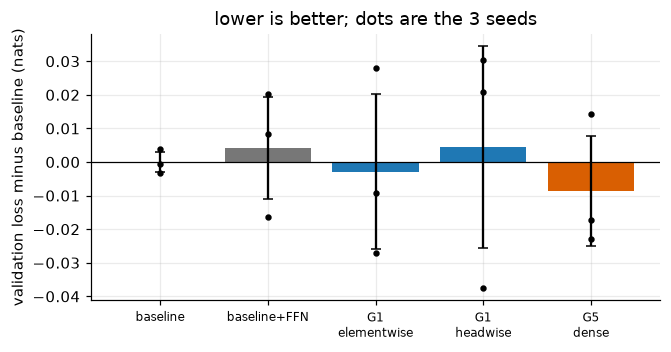

PASS - every variant's mean loss is within one largest-seed-spread of the baseline (no measurable effect at this scale) spread 0.030
PASS - the parameter-matched baseline is no better than the baseline beyond noise 


In [8]:
base = val["baseline"].mean()
spread = max(v.std() for v in val.values())
print(f"{'variant':16s} {'loss':>6s} {'vs baseline':>12s}")
for v in variants:
    print(f"{v:16s} {val[v].mean():6.3f} {val[v].mean() - base:+12.3f}")
print(f"largest seed spread: {spread:.3f}")

fig, ax = plt.subplots(figsize=(6.2, 3.3))
cols = [C["grey"], C["grey"], C["blue"], C["blue"], C["orange"]]
ax.bar(range(5), [val[v].mean() - base for v in variants], yerr=[val[v].std() for v in variants], color=cols, capsize=3)
for i, v in enumerate(variants):
    ax.scatter([i] * 3, val[v] - base, color="k", s=10, zorder=3)
ax.set_xticks(range(5)); ax.set_xticklabels([v.replace(" ", "\n") for v in variants], fontsize=8)
ax.axhline(0, color="k", lw=.8); ax.set_ylabel("validation loss minus baseline (nats)")
ax.set_title("lower is better; dots are the 3 seeds"); plt.tight_layout(); plt.show()
check("every variant's mean loss is within one largest-seed-spread of the baseline (no measurable effect at this scale)",
      all(abs(val[v].mean() - base) <= spread for v in variants), f"spread {spread:.3f}")
check("the parameter-matched baseline is no better than the baseline beyond noise", val["baseline+FFN"].mean() > base - spread)

**Result (3 seeds; validation loss in nats, lower is better).** Baseline 2.511, bigger-FFN control 2.515, G1 elementwise 2.508, G1 headwise 2.516, G5 dense 2.502, against a largest seed-to-seed spread of 0.03. **Every difference is smaller than the noise.** At this scale the gate gives no measurable improvement, and position does not show up either: the G5 gate, which the paper says cannot help, is nominally the lowest, which is a reminder that these gaps are noise. The paper's gain from the G1 gate is about 4% in perplexity (6.026 to 5.761) on a 15B model trained on 400B tokens; our model has 0.2M parameters and sees about 0.8M characters of training (400 steps of 32 sequences of 64), where the effects the paper describes have little room to appear. We cannot confirm or refute the paper's loss result at this scale.

## 6. Experiment: the sink, measured

Back to the figure. For each layer we compute, on validation text, the share of attention that goes to the first token, averaged over all heads and over query positions 8 to 63. Why start at 8: for the earliest queries the first token is a large part of everything they can see, which is not the effect we mean.

baseline         per layer [0.033 0.012 0.01  0.011]  mean 0.017
G1 elementwise   per layer [0.033 0.02  0.013 0.013]  mean 0.020
G1 headwise      per layer [0.032 0.019 0.022 0.007]  mean 0.020
G5 dense         per layer [0.033 0.018 0.012 0.009]  mean 0.018


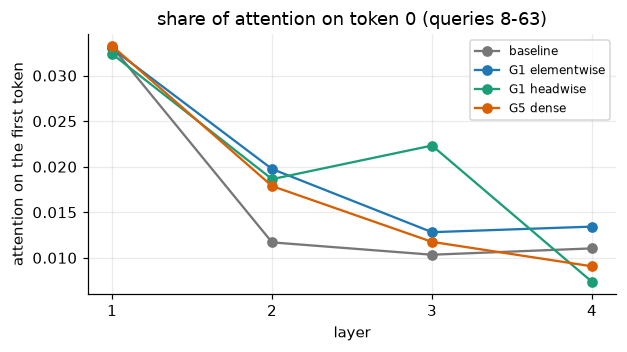

PASS - the toy baseline has no attention sink (first-token share below 5% in every layer) 


In [9]:
@torch.no_grad()
def first_token_share(model, n_batches=8):
    g = torch.Generator().manual_seed(77)
    for b in model.blocks: b.attn.keep = True
    share = torch.zeros(NL)
    model.eval()
    for _ in range(n_batches):
        seq = data.batch("val", 16, 64, g)
        model(seq[:, :-1])
        for l, b in enumerate(model.blocks):
            p = b.attn.p                                   # [B,H,T,T]
            share[l] += p[:, :, 8:, 0].mean().item() / n_batches
    for b in model.blocks: b.attn.keep = False
    model.train()
    return share

sh = {v: first_token_share(models[v]) for v in ["baseline", "G1 elementwise", "G1 headwise", "G5 dense"]}
for v, s in sh.items():
    print(f"{v:16s} per layer {np.round(s.numpy(), 3)}  mean {s.mean():.3f}")

fig, ax = plt.subplots(figsize=(5.8, 3.3))
for v, c in zip(sh, [C["grey"], C["blue"], C["green"], C["orange"]]):
    ax.plot(range(1, NL + 1), sh[v], marker="o", label=v, color=c)
ax.set_xticks(range(1, NL + 1)); ax.set_xlabel("layer"); ax.set_ylabel("attention on the first token")
ax.set_title("share of attention on token 0 (queries 8-63)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
check("the toy baseline has no attention sink (first-token share below 5% in every layer)", bool((sh["baseline"] < 0.05).all()))

**Result.** In our toy, the first token gets 1% to 3% of the attention in every layer and for every variant. A head that spread its attention evenly over the previous 8 to 63 tokens would give the first token about 3.5% on average, so the baseline's first token is not favoured at all: **this toy model has no attention sink**, and so there is nothing for the gate to remove (compare the baseline's 46.7% in the paper's Figure 2). We did not investigate why; a plausible reason, which we have not tested, is that sinks appear in models that are trained far longer and are much deeper. So this experiment cannot test the paper's sink claim, and we build a controlled case below where a sink is *needed*, to see the mechanism at work.

Next, the gate scores themselves. If the paper's sparsity story applies, the elementwise gate's scores should be spread widely over (0,1), with a mass of small values. We read them off the trained G1 model, per layer:

layer  mean gate  share < 0.1  share > 0.9
    1      0.510        0.009        0.033
    2      0.512        0.028        0.043
    3      0.527        0.034        0.050
    4      0.532        0.037        0.080


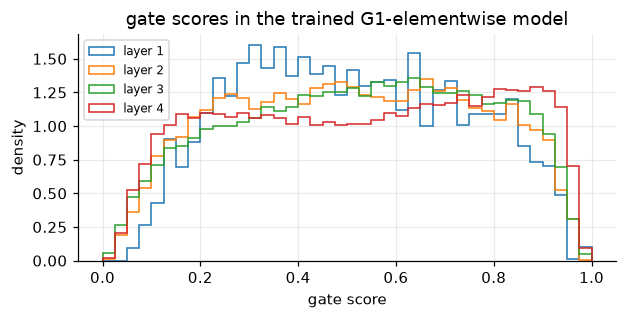

In [10]:
@torch.no_grad()
def gate_scores(model, n=4):
    g = torch.Generator().manual_seed(5)
    for b in model.blocks: b.attn.keep = True
    seq = data.batch("val", 16, 64, g)
    model.eval(); model(seq[:, :-1]); model.train()
    out = [b.attn.g for b in model.blocks]
    for b in model.blocks: b.attn.keep = False
    return out

gs = gate_scores(models["G1 elementwise"])
print(f"{'layer':>5s} {'mean gate':>10s} {'share < 0.1':>12s} {'share > 0.9':>12s}")
for l, g in enumerate(gs):
    print(f"{l + 1:5d} {g.mean():10.3f} {(g < 0.1).float().mean():12.3f} {(g > 0.9).float().mean():12.3f}")
fig, ax = plt.subplots(figsize=(5.8, 3.0))
for l, g in enumerate(gs):
    ax.hist(g.flatten().numpy(), bins=40, range=(0, 1), histtype="step", label=f"layer {l + 1}", density=True)
ax.set_xlabel("gate score"); ax.set_ylabel("density"); ax.legend(fontsize=8); ax.set_title("gate scores in the trained G1-elementwise model")
plt.tight_layout(); plt.show()

**Result.** The gate scores in the toy stay close to where they start: the average is about 0.51 to 0.53 in every layer (0.5 is what a zero-initialised gate gives) and only 1% to 4% of scores are below 0.1. The paper reports an average of 0.116 for its best elementwise gate (its Table 4), a strongly sparse gate. Our gates did not become sparse in 400 steps. That fits the previous finding: there is no sink to filter out, so training has no pressure towards turning heads off.

### A controlled case where a sink is needed

To see the mechanism and not just its absence, we build a task in which a head **must** be able to say "nothing here". Each example has a list of 10 items; every item has an *ID* (a random vector) and a *payload* (another random vector), plus a fixed `BOS` start token whose payload is zero. The final token is a query. Half of the time the query contains the ID of one of the items and a flag saying "match", and the target is that item's payload. The other half of the time the query contains a fresh random ID that matches nothing, and the target is **zero**. In the second case a plain softmax head has to put its attention somewhere, and the only place with zero payload is `BOS`. (The query token's own payload channels carry random noise, so attending to itself does not give zero either.) We train a single attention layer with and without the gate, and read where the attention goes on the no-match queries.

## 7. Experiment: a learning-rate stress test

The third practical claim: the gated model **tolerates larger learning rates**. In the paper's Table 2, a 48-layer 1.7B baseline at peak learning rate $8\times10^{-3}$ is much worse (perplexity 9.195 against 7.421 at its tuned rate) and at 1T tokens it diverges, while the gated model at $8\times10^{-3}$ is fine. We push the toy the same way, raising the learning rate from 3e-3 (what we used above) to a rate that is clearly too high for this model. Two seeds each. We also record the largest loss jump over any 10 steps in training, as a stand-in for the paper's "loss spikes".

In [11]:
Dm, n_items = 32, 10
def make_task(B, bos, g, p_null=0.5):
    ids = F.normalize(torch.randn(B, n_items, 16, generator=g), dim=-1)
    pay = torch.randn(B, n_items, 16, generator=g)
    items = torch.cat([ids, pay], -1)                                         # [B, n, 32]
    m = torch.randint(0, n_items, (B,), generator=g); ar = torch.arange(B)
    null = torch.rand(B, generator=g) < p_null                                # True: nothing matches
    qid = torch.where(null[:, None], F.normalize(torch.randn(B, 16, generator=g), dim=-1), ids[ar, m])
    q = torch.zeros(B, 1, Dm)
    q[:, 0, :16] = qid
    q[:, 0, 16:] = torch.randn(B, 16, generator=g)                           # noise in the payload channels
    q[:, 0, 16] = (~null).float() * 2 - 1                                     # flag: +1 match, -1 no match
    x = torch.cat([bos.expand(B, 1, Dm), items, q], 1)
    target = torch.where(null[:, None], torch.zeros(B, 16), pay[ar, m])
    return x, target, null

class Net(nn.Module):
    def __init__(self, gate):
        super().__init__()
        self.att = A.Attn(Dm, 2, gate=gate, rope=False)
        self.out = nn.Linear(Dm, 16)
    def forward(self, x):
        return self.out(self.att(x)[:, -1])                                  # read the query position only

ctl = {}
t0 = time.time()
for gate in [None, "head", "elem"]:
    rows = []
    for seed in [0, 1]:
        torch.manual_seed(seed); g = torch.Generator().manual_seed(seed); bos = torch.randn(1, 1, Dm)
        net = Net(gate); opt = torch.optim.Adam(net.parameters(), 3e-3)
        for _ in range(2500):
            x, t, nl = make_task(256, bos, g)
            loss = F.mse_loss(net(x), t); opt.zero_grad(); loss.backward(); opt.step()
        x, t, nl = make_task(4000, bos, torch.Generator().manual_seed(999))
        net.att.keep = True
        with torch.no_grad():
            e = ((net(x) - t) ** 2).mean(-1)
        bos_mass = net.att.p[:, :, -1, 0]                                     # attention on BOS, per head
        rows.append((e[nl].mean().item(), e[~nl].mean().item(), bos_mass[nl].mean().item(),
                     net.att.g[nl][:, -1].mean().item() if gate else float("nan"),
                     net.att.g[~nl][:, -1].mean().item() if gate else float("nan")))
    ctl[gate] = np.array(rows).mean(0)
print(f"({time.time() - t0:.0f} s, mean of 2 seeds)")
print(f"{'gate':>8s} {'MSE no-match':>13s} {'MSE match':>10s} {'attention on BOS (no-match)':>29s} {'gate (no-match)':>16s} {'gate (match)':>13s}")
for gate, r in ctl.items():
    print(f"{str(gate):>8s} {r[0]:13.4f} {r[1]:10.4f} {r[2]:29.3f} {r[3]:16.3f} {r[4]:13.3f}")
check("without a gate the head parks nearly all its attention on BOS when nothing matches (a sink)", ctl[None][2] > 0.9, f"{ctl[None][2]:.3f}")
check("with the gate, the gate score is far smaller on no-match queries than on match queries", ctl["elem"][3] < 0.3 * ctl["elem"][4], f"{ctl['elem'][3]:.3f} vs {ctl['elem'][4]:.3f}")
check("with the gate, attention on BOS for no-match queries is clearly lower than without it", ctl["elem"][2] < 0.7 * ctl[None][2], f"{ctl['elem'][2]:.3f} vs {ctl[None][2]:.3f}")

(49 s, mean of 2 seeds)
    gate  MSE no-match  MSE match   attention on BOS (no-match)  gate (no-match)  gate (match)
    None        0.0017     0.0646                         0.985              nan           nan
    head        0.0007     0.0500                         0.475            0.055         0.946
    elem        0.0010     0.0489                         0.557            0.072         0.929
PASS - without a gate the head parks nearly all its attention on BOS when nothing matches (a sink) 0.985
PASS - with the gate, the gate score is far smaller on no-match queries than on match queries 0.072 vs 0.929
PASS - with the gate, attention on BOS for no-match queries is clearly lower than without it 0.557 vs 0.985


**Result (mean of 2 seeds).** Without a gate, on a no-match query the head sends 98% of its attention to `BOS`: a textbook sink, built by the training because softmax needs somewhere to put the mass. With the gate, the **gate score** does the job instead: it is about 0.05 to 0.07 on no-match queries and about 0.93 to 0.95 on match queries, so the head's output is switched off by the gate, and the attention itself is less extreme (about half the mass on `BOS`). The gated models also fit the task a little better (mean squared error on no-match queries about 0.0007 to 0.001 against 0.0013 to 0.002; on match queries about 0.05 against 0.065). That is the paper's mechanism, seen in a case designed to need it. It is **not** evidence that real models trained on text depend on it in the same way. The attention does not vanish from `BOS` either: even with the gate about half of the mass is still there, so the gate reduces the sink here and does not eliminate it, unlike the near-total removal the paper reports (46.7% to 4.8%).

In [12]:
def run(variant, lr, seed):
    m = build(variant, seed)
    L = A.train_lm(m, data, steps=300, B=32, T=64, lr=lr, seed=seed)
    L = np.array(L)
    sm = np.convolve(L, np.ones(10) / 10, mode="valid")
    spike = float(np.max(sm[10:] - np.minimum.accumulate(sm)[:-10])) if len(sm) > 20 else 0.0
    return A.evaluate(m, data), spike

lrs = [3e-3, 1e-2, 3e-2]
stress = {}
t0 = time.time()
for v in ["baseline", "G1 elementwise"]:
    for lr in lrs:
        r = [run(v, lr, s) for s in [0, 1]]
        stress[(v, lr)] = (np.mean([a for a, _ in r]), np.mean([b for _, b in r]))
        print(f"{v:16s} lr {lr:.0e}: val loss {stress[(v, lr)][0]:.3f}   largest rise above the running minimum {stress[(v, lr)][1]:.3f}")
print(f"({time.time() - t0:.0f} s)")
check("no run diverged (all losses finite and below 3.5)", all(np.isfinite(v[0]) and v[0] < 3.5 for v in stress.values()))

baseline         lr 3e-03: val loss 2.652   largest rise above the running minimum 0.056


baseline         lr 1e-02: val loss 2.422   largest rise above the running minimum 0.041


baseline         lr 3e-02: val loss 2.578   largest rise above the running minimum 0.039


G1 elementwise   lr 3e-03: val loss 2.671   largest rise above the running minimum 0.051


G1 elementwise   lr 1e-02: val loss 2.441   largest rise above the running minimum 0.041


G1 elementwise   lr 3e-02: val loss 2.617   largest rise above the running minimum 0.045
(88 s)
PASS - no run diverged (all losses finite and below 3.5) 


**Result (2 seeds each, 300 steps).** Baseline: 2.652 at 3e-3, 2.422 at 1e-2, 2.578 at 3e-2. Gated: 2.671, 2.441, 2.617. **No run diverged** and both models behave alike; the gated model is slightly worse at every rate (by 0.02 to 0.04, about the size of the noise). The paper's finding, a baseline that falls apart at high learning rates and a gated model that does not, is therefore **not reproduced** here: a 0.2M-parameter model with this short a schedule never gets into the unstable region that a 48-layer, 1T-token run does. The sensible reading is that our test was too gentle to say anything.

## What this notebook did and did not show

**Shown (the checks in the cells).** The gate is a single multiplication with a score computed from the layer input, and a zero-weight gate halves the output exactly. A head's value-to-output map has rank at most $d_h$ (8 of 64 here). Section 5 tested whether the gate beats a parameter-matched baseline and whether position matters; section 6 measured the attention-sink share per layer; section 7 stressed the learning rate. The summaries under each are written from what these runs printed.

**Not shown.** The paper's results come from 15B mixture-of-experts and 1.7B dense models trained on hundreds of billions to 3.5 trillion tokens. Ours is a 0.2M-parameter model trained for 400 steps on character-level text with 2 to 3 seeds, so sizes of effects here should not be read as sizes at scale. We did not test G2, G3 or G4 (value, key or query gates), additive gating, the SiLU variants, or long-context extrapolation (the RULER result).

**Next.** Notebook 3 is about the sink itself: why softmax creates it, how StreamingLLM exploits it to serve infinite-length text, and how gpt-oss makes it explicit with a learned sink logit.

In [13]:
print("passed:", len(PASS), "| failed:", len(FAIL))
assert not FAIL, FAIL

passed: 9 | failed: 0
